Imports and data

Data files pulled from these locations: 

NGC 4326 : https://www.legacysurvey.org/viewer/data-for-radec/?ra=185.7983&dec=6.0714&layer=ls-dr11&ralo=185.6788&rahi=185.9238&declo=6.0151&dechi=6.1479
NGC 4246 : https://www.legacysurvey.org/viewer/data-for-radec/?ra=184.4926&dec=7.1856&layer=ls-dr11&ralo=184.3659&rahi=184.6109&declo=7.1129&dechi=7.2454
NGC 4622 : https://www.legacysurvey.org/viewer/data-for-radec/?ra=190.6566&dec=-40.7450&layer=ls-dr11&ralo=190.5268&rahi=190.7718&declo=-40.7915&dechi=-40.6903
NGC 3642 : https://www.legacysurvey.org/viewer/data-for-radec/?ra=170.5700&dec=59.0739&layer=ls-dr11&ralo=170.0440&rahi=171.0238&declo=58.9222&dechi=59.1969
NGC 3054 : https://www.legacysurvey.org/viewer/data-for-radec/?ra=148.6189&dec=-25.7031&layer=ls-dr11&ralo=148.5032&rahi=148.7482&declo=-25.7676&dechi=-25.6473

Notebook Routine: After reading in the images from the DESI Legacy Survey, we use Photutils to make ellipses for our photometric measurements of our galaxy sample above. These ellipses are initially made in DS9, where we make a dictionary called "initparams" that give us the

In [1]:
#import 
from astropy.stats import sigma_clipped_stats
from astropy.visualization import SqrtStretch
from astropy.visualization.mpl_normalize import ImageNormalize
from astropy.wcs import WCS
from astropy.io import fits
import glob
import os
from scipy.stats import scoreatpercentile
import astropy.units as u
from scipy import stats

from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection
from matplotlib import pyplot as plt
import numpy as np
from matplotlib import colors


from astropy.nddata import CCDData
#from ccdproc import ImageFileCollection, Combiner, combine
from ccdproc import wcs_project

Image display functions pulled from the homework. These come from the surface photometry computational assignment. 

In [2]:
def imdisplay(image, v1perc=10, v2perc=95, logscale=True):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    fig,ax = plt.subplots(figsize=(6,6))
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    print(v1,v2)
    if (logscale):
        im = ax.imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
    else:
        im = ax.imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')
        
    cbar = fig.colorbar(im, ax=ax, fraction=0.04)
    cbar.ax.set_ylabel('counts')
    return fig,ax


def imdisplay2(image, v1perc=10, v2perc=95, logscale=True):
    '''
    display two copies of an image side-by-side
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    #this makes two horizontal figures 
    fig,axs = plt.subplots(1,2,figsize=(12,6))
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    print(f"v1 = {v1:5.2f}, v2 = {v2:5.2f}")
    if (logscale):
        #plot the two figures side by side
        im0 = axs[0].imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
        im1 = axs[1].imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
    else:
        im0 = axs[0].imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')
        im1 = axs[1].imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')

    #plot colorbars for each subplot
    cbar0 = fig.colorbar(im0, ax=axs[0], fraction=0.04)
    cbar0.ax.set_ylabel('counts')
    cbar1 = fig.colorbar(im1, ax=axs[1], fraction=0.04)
    cbar1.ax.set_ylabel('counts')
    return fig,axs

Data dirrectory, be sure to change to reflect your local machine! This code is the skeleton of the image plots. 

In [3]:
#put your data directory here
datadir = '/home/nathaniel-sexton/ASTR596/Data/Capstone' ## in a terminal, cd to the data directory and then use pwd to get the path. Copy that path to this string. 
os.chdir(datadir)

Image dictionary init: 

In [4]:
#initialize dictionaries that contains names of images and headers
imname = {}
data = {}
header = {}
corners = {}
bkgdim = {}

#statistics of background
bkgmode = {}
bkgmed = {}

Read in data: 

4.1706765623530364e-05 2.065298566104932
1.8366183503531076e-05 0.760763405680775
7.906777726020666e-05 0.8483851545454266
5.162178887985636e-05 0.9362963367704058
4.840423702262347e-05 9.602955817247718


Text(0.5, 1.0, 'NGC4622')

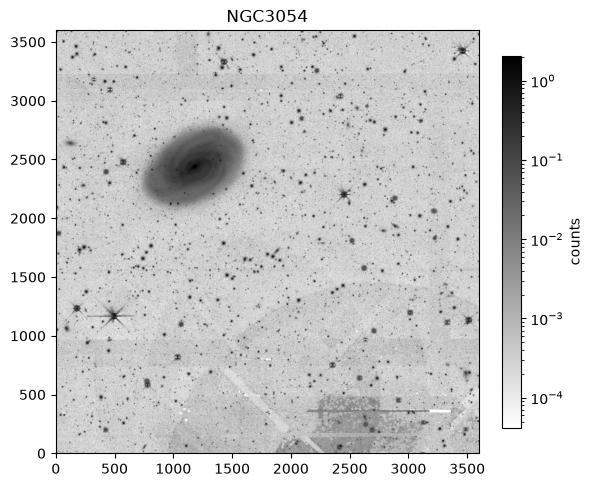

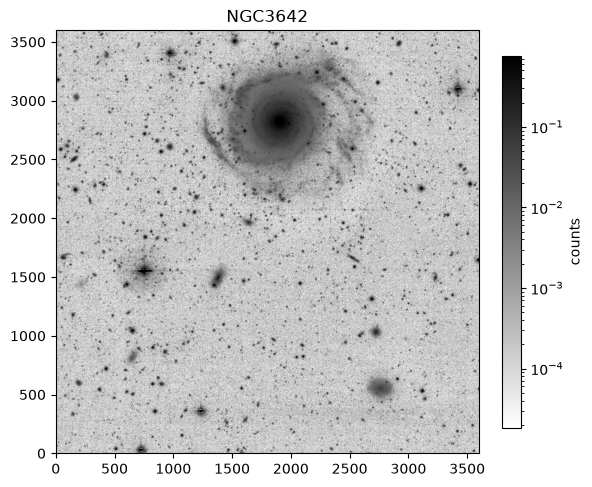

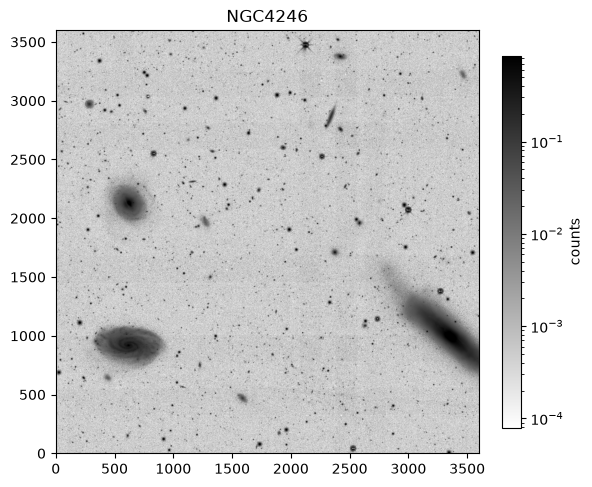

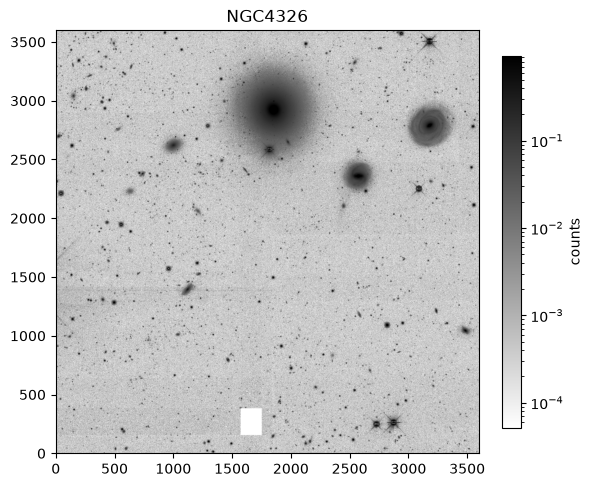

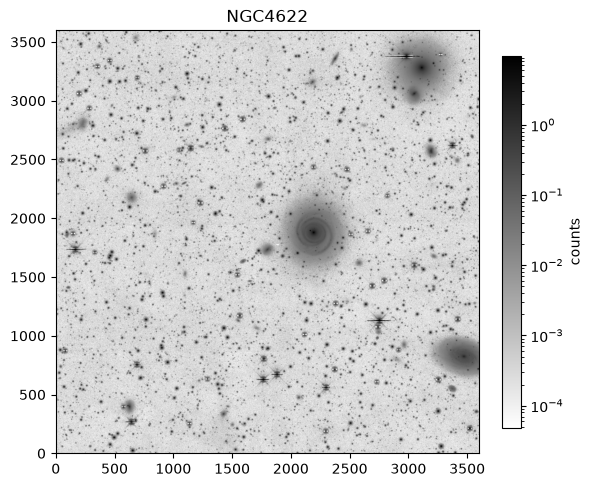

In [25]:
galname = 'NGC3054'
imname[galname] = 'NGC3054_legacysurvey-1485m257-image-r.fits.fz'

#read fits image
data[galname],header[galname] = fits.getdata(imname[galname], header=True)

#display the data
fig,ax =imdisplay(data[galname],v1perc=44.5,v2perc=99.9,logscale=True)

#add an image title
plt.title(galname)


galname = 'NGC3642'
imname[galname] = 'NGC3642_legacysurvey-1705p590-image-r.fits.fz'

#read fits image
data[galname],header[galname] = fits.getdata(imname[galname], header=True)

#display the data
fig,ax =imdisplay(data[galname],v1perc=43,v2perc=99.9,logscale=True)

#add an image title
plt.title(galname)


galname = 'NGC4246'
imname[galname] = 'NGC4246_legacysurvey-1844p072-image-r.fits.fz'

#read fits image
data[galname],header[galname] = fits.getdata(imname[galname], header=True)

#display the data
fig,ax =imdisplay(data[galname],v1perc=46.5,v2perc=99.9,logscale=True)

#add an image title
plt.title(galname)


galname = 'NGC4326'
imname[galname] = 'NGC4326_legacysurvey-1858p060-image-r.fits.fz'

#read fits image
data[galname],header[galname] = fits.getdata(imname[galname], header=True)

#display the data
fig,ax =imdisplay(data[galname],v1perc=45.5,v2perc=99.9,logscale=True)

#add an image title
plt.title(galname)


galname = 'NGC4622'
imname[galname] = 'NGC4622_legacysurvey-1906m407-image-r.fits.fz'

#read fits image
data[galname],header[galname] = fits.getdata(imname[galname], header=True)

#display the data
fig,ax =imdisplay(data[galname],v1perc=42,v2perc=99.9,logscale=True)

#add an image title
plt.title(galname)

These are the Legacy images of our galaxies. We did not do a background-subtraction method because according to the Legacy survey, these images have already had background subtraction accounted for. 

In [119]:
#initialize the dictionary containing the intial parameters for the ellipse fitting
initparams = {}

#initiparams is a dictionary which contains an entry for each galaxy.  That dictionary in turns points to another dictionary with the parameters.
galname = 'NGC3054'
initparams[galname] = {}
#centroids [pixels]
initparams[galname]['xcen'] = 1183
initparams[galname]['ycen'] = 2440
#semi-major axis [pixels]
initparams[galname]['sma'] = 112
#semin-minor axis [pixels]
initparams[galname]['smina'] = 65
#ellipticity = 1-b/a
initparams[galname]['ellip'] = 1. - initparams[galname]['smina'] / initparams[galname]['sma'] 
#position angle, counterclockwise from the positive x-direction (right) [degrees]
initparams[galname]['PA'] = 35


#initiparams is a dictionary which contains an entry for each galaxy.  That dictionary in turns points to another dictionary with the parameters.
galname = 'NGC3642'
initparams[galname] = {}
#centroids [pixels]
initparams[galname]['xcen'] = 1908
initparams[galname]['ycen'] = 2824
#semi-major axis [pixels]
initparams[galname]['sma'] = 246
#semin-minor axis [pixels]
initparams[galname]['smina'] = 240
#ellipticity = 1-b/a
initparams[galname]['ellip'] = 1. - initparams[galname]['smina'] / initparams[galname]['sma'] 
#position angle, counterclockwise from the positive x-direction (right) [degrees]
initparams[galname]['PA'] = 30


#initiparams is a dictionary which contains an entry for each galaxy.  That dictionary in turns points to another dictionary with the parameters.
galname = 'NGC4246'
initparams[galname] = {}
#centroids [pixels]
initparams[galname]['xcen'] = 621
initparams[galname]['ycen'] = 920
#semi-major axis [pixels]
initparams[galname]['sma'] = 103
#semin-minor axis [pixels]
initparams[galname]['smina'] = 63
#ellipticity = 1-b/a
initparams[galname]['ellip'] = 1. - initparams[galname]['smina'] / initparams[galname]['sma'] 
#position angle, counterclockwise from the positive x-direction (right) [degrees]
initparams[galname]['PA'] = 0


#initiparams is a dictionary which contains an entry for each galaxy.  That dictionary in turns points to another dictionary with the parameters.
galname = 'NGC4326'
initparams[galname] = {}
#centroids [pixels]
initparams[galname]['xcen'] = 3182
initparams[galname]['ycen'] = 2792
#semi-major axis [pixels]
initparams[galname]['sma'] = 45
#semin-minor axis [pixels]
initparams[galname]['smina'] = 37
#ellipticity = 1-b/a
initparams[galname]['ellip'] = 1. - initparams[galname]['smina'] / initparams[galname]['sma'] 
#position angle, counterclockwise from the positive x-direction (right) [degrees]
initparams[galname]['PA'] = 18


#initiparams is a dictionary which contains an entry for each galaxy.  That dictionary in turns points to another dictionary with the parameters.
galname = 'NGC4622'
initparams[galname] = {}
#centroids [pixels]
initparams[galname]['xcen'] = 2196
initparams[galname]['ycen'] = 1880
#semi-major axis [pixels]
initparams[galname]['sma'] = 93
#semin-minor axis [pixels]
initparams[galname]['smina'] = 89
#ellipticity = 1-b/a
initparams[galname]['ellip'] = 1. - initparams[galname]['smina'] / initparams[galname]['sma'] 
#position angle, counterclockwise from the positive x-direction (right) [degrees]
initparams[galname]['PA'] = 0

By simply moving the cursor to the center of the DS9 image, we include our estimates of the center of each image in pixels. Using DS9, we fit an ellipse around each galaxy.
This gives us an estimate of the semimajor and semiminor axes of the galaxy. The ellipse  also provided information on its position angle, measured from southeast. 

In [83]:
from photutils.isophote import EllipseGeometry
from photutils.aperture import EllipticalAperture

#define an empty dictionary that will contain the EllipseGeometry instance
geometry = {}

112 0.4196428571428571
4.1706765623530364e-05 10.000043869018555


Text(0.5, 1.0, 'NGC3054')

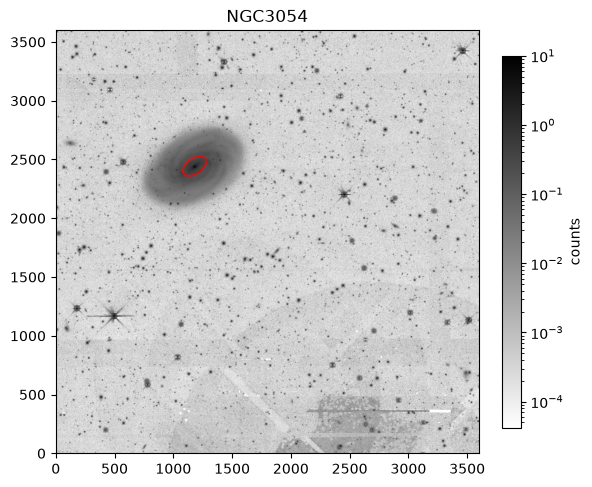

In [84]:
#set up the EllipseGeometry instance with the right initial guess parameters
galname = 'NGC3054'
geometry[galname] = EllipseGeometry(x0 = initparams[galname]['xcen'], 
                                      y0 = initparams[galname]['ycen'],
                                      sma = initparams[galname]['sma'],
                                      eps = initparams[galname]['ellip'],
                                      pa = initparams[galname]['PA'] * np.pi/180)   #convert into radians

print(geometry[galname].sma,geometry[galname].eps )
#make an aperture to overplot so that we can check if it makes sense
aper = EllipticalAperture((geometry[galname].x0, geometry[galname].y0), geometry[galname].sma, 
                          geometry[galname].sma * (1.-geometry[galname].eps), geometry[galname].pa)

#plot our image
#fig,ax = plt.subplots(figsize=(6,6))
fig,ax = imdisplay(data[galname],v1perc=44.5,v2perc=99.99,logscale=True)
aper.plot(color='red')
plt.title(galname)

246 0.024390243902439046
1.8366183503531076e-05 10.00002670288086


Text(0.5, 1.0, 'NGC3642')

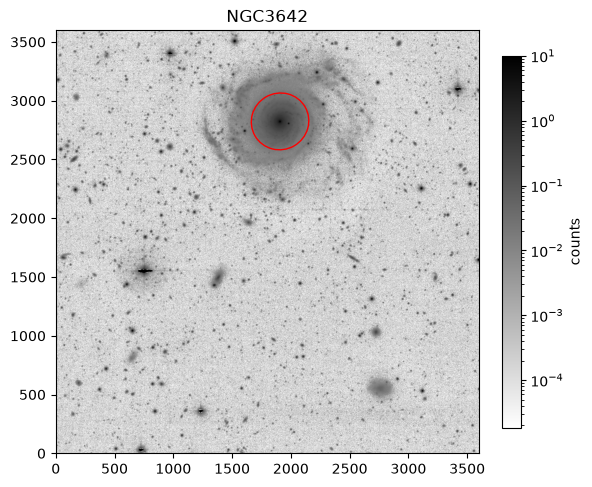

In [120]:
#set up the EllipseGeometry instance with the right initial guess parameters
galname = 'NGC3642'
geometry[galname] = EllipseGeometry(x0 = initparams[galname]['xcen'], 
                                      y0 = initparams[galname]['ycen'],
                                      sma = initparams[galname]['sma'],
                                      eps = initparams[galname]['ellip'],
                                      pa = initparams[galname]['PA'] * np.pi/180)   #convert into radians

print(geometry[galname].sma,geometry[galname].eps )
#make an aperture to overplot so that we can check if it makes sense
aper = EllipticalAperture((geometry[galname].x0, geometry[galname].y0), geometry[galname].sma, 
                          geometry[galname].sma * (1.-geometry[galname].eps), geometry[galname].pa)

#plot our image
#fig,ax = plt.subplots(figsize=(6,6))
fig,ax = imdisplay(data[galname],v1perc=43,v2perc=99.99,logscale=True)
aper.plot(color='red')
plt.title(galname)

103 0.38834951456310685
7.906777726020666e-05 9.999992370605469


Text(0.5, 1.0, 'NGC4246')

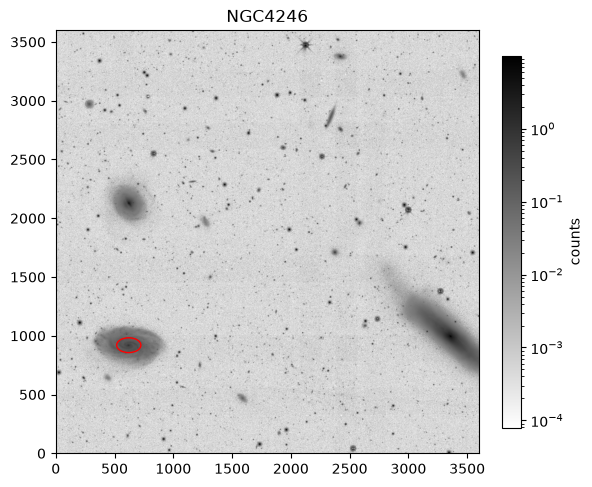

In [86]:
#set up the EllipseGeometry instance with the right initial guess parameters
galname = 'NGC4246'
geometry[galname] = EllipseGeometry(x0 = initparams[galname]['xcen'], 
                                      y0 = initparams[galname]['ycen'],
                                      sma = initparams[galname]['sma'],
                                      eps = initparams[galname]['ellip'],
                                      pa = initparams[galname]['PA'] * np.pi/180)   #convert into radians

print(geometry[galname].sma,geometry[galname].eps )
#make an aperture to overplot so that we can check if it makes sense
aper = EllipticalAperture((geometry[galname].x0, geometry[galname].y0), geometry[galname].sma, 
                          geometry[galname].sma * (1.-geometry[galname].eps), geometry[galname].pa)

#plot our image
#fig,ax = plt.subplots(figsize=(6,6))
fig,ax = imdisplay(data[galname],v1perc=46.5,v2perc=99.99,logscale=True)
aper.plot(color='red')
plt.title(galname)

45 0.1777777777777778
5.162178887985636e-05 10.000020980834961


Text(0.5, 1.0, 'NGC4326')

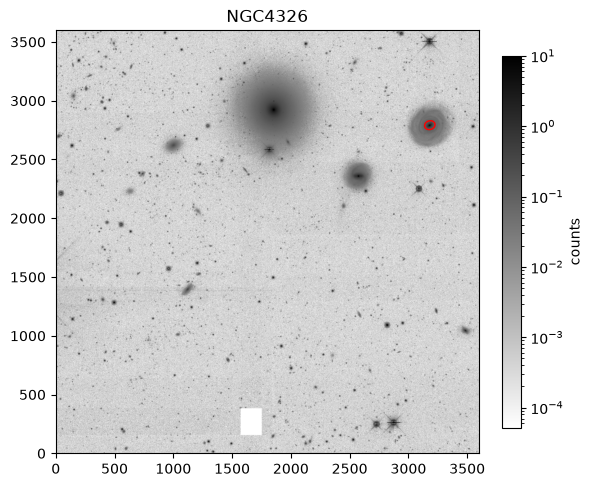

In [87]:
#set up the EllipseGeometry instance with the right initial guess parameters
galname = 'NGC4326'
geometry[galname] = EllipseGeometry(x0 = initparams[galname]['xcen'], 
                                      y0 = initparams[galname]['ycen'],
                                      sma = initparams[galname]['sma'],
                                      eps = initparams[galname]['ellip'],
                                      pa = initparams[galname]['PA'] * np.pi/180)   #convert into radians

print(geometry[galname].sma,geometry[galname].eps )
#make an aperture to overplot so that we can check if it makes sense
aper = EllipticalAperture((geometry[galname].x0, geometry[galname].y0), geometry[galname].sma, 
                          geometry[galname].sma * (1.-geometry[galname].eps), geometry[galname].pa)

#plot our image
#fig,ax = plt.subplots(figsize=(6,6))
fig,ax = imdisplay(data[galname],v1perc=45.5,v2perc=99.99,logscale=True)
aper.plot(color='red')
plt.title(galname)

93 0.043010752688172005
4.840423702262347e-05 10.000045776367188


Text(0.5, 1.0, 'NGC4622')

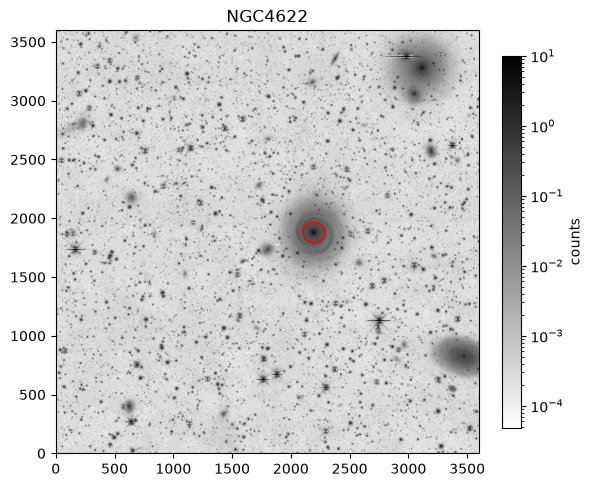

In [109]:
#set up the EllipseGeometry instance with the right initial guess parameters
galname = 'NGC4622'
geometry[galname] = EllipseGeometry(x0 = initparams[galname]['xcen'], 
                                      y0 = initparams[galname]['ycen'],
                                      sma = initparams[galname]['sma'],
                                      eps = initparams[galname]['ellip'],
                                      pa = initparams[galname]['PA'] * np.pi/180)   #convert into radians

print(geometry[galname].sma,geometry[galname].eps )
#make an aperture to overplot so that we can check if it makes sense
aper = EllipticalAperture((geometry[galname].x0, geometry[galname].y0), geometry[galname].sma, 
                          geometry[galname].sma * (1.-geometry[galname].eps), geometry[galname].pa)

#plot our image
#fig,ax = plt.subplots(figsize=(6,6))
fig,ax = imdisplay(data[galname],v1perc=42,v2perc=99.99,logscale=True)
aper.plot(color='red')
plt.title(galname)

The above lines of code take our ellipses from DS9, and place them on our images, using parameters from the initial ellipse-fitting section. 

In [89]:
from photutils.isophote import Ellipse

#initialize dictionary for ellipse fitting
ellipse = {}
isolist = {}

xcenav = {}
ycenav = {}
epsav = {}
paav = {}

In [90]:
def plotellipse(isolist):
    plt.figure(figsize=(8, 8))
    plt.subplots_adjust(hspace=0.35, wspace=0.35)

    #plot the semi-major axis vs. the ellipticity
    plt.subplot(2, 2, 1)
    plt.errorbar(isolist.sma, isolist.eps, yerr=isolist.ellip_err,
                 fmt='o', markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('Ellipticity')
    
    #plot the semi-major axis vs. the PA
    plt.subplot(2, 2, 2)
    plt.errorbar(isolist.sma, isolist.pa / np.pi * 180.0,
                 yerr=isolist.pa_err / np.pi * 80.0, fmt='o', markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('PA (deg)')

    #plot the semi-major axis vs. the x center of that ellipse
    plt.subplot(2, 2, 3)
    plt.errorbar(isolist.sma, isolist.x0, yerr=isolist.x0_err, fmt='o',
                 markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('x0')
    
    #plot the semi-major axis vs. the y center of that ellipse
    plt.subplot(2, 2, 4)
    plt.errorbar(isolist.sma, isolist.y0, yerr=isolist.y0_err, fmt='o',
                 markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('y0')

In [91]:
#this subroutine will plot every other isophote on top of the galaxy image
def plotaper(galname, image, isophote_list,vminperc=40,vmaxperc=99.99):

    #plot image
    #plt.subplots(figsize=(6,6))
    fig,ax = imdisplay2(image,v1perc=vminperc,v2perc=vmaxperc,logscale=True)

    #Loop through all apertures starting at the first (not zero) and going to every other aperture
    for i in range(1, len(isophote_list.sma),2):
        #create an elliptical aperture with the the correct geometry.  
        #Task is described here https://photutils.readthedocs.io/en/stable/api/photutils.aperture.EllipticalAperture.html#photutils.aperture.EllipticalAperture
        aperiter = EllipticalAperture((isophote_list.x0[i], isophote_list.y0[i]), isophote_list.sma[i], 
                                      isophote_list.sma[i] * (1-isophote_list.eps[i]), isophote_list.pa[i])
    
        #overplot apertures
        aperiter.plot(ax=ax[0],color='red')

    #plot the isophotes that have parameters fixed to the median parameters of all but the "apmin" inner isphotes
    #compute median isophote parameters ignoring inner isophotes.  This is because the inner isophotes all tend to be rather circular
    apmin = 20   #the minimum inner isophote in terms of isophote number.
    xcenav = np.median(isophote_list.x0[apmin:])
    ycenav = np.median(isophote_list.y0[apmin:])
    epsav = np.median(isophote_list.eps[apmin:])
    paav = np.median(isophote_list.pa[apmin:])
    
    #fig,ax = imdisplay(image,v1perc=vminperc,v2perc=vmaxperc,logscale=True)
    for i in range(1, len(isophote_list.sma),2):
        #create an elliptical aperture with the the correct geometry.  
        #Task is described here https://photutils.readthedocs.io/en/stable/api/photutils.aperture.EllipticalAperture.html#photutils.aperture.EllipticalAperture
        aperiter = EllipticalAperture((xcenav, ycenav), isophote_list.sma[i], 
                                      isophote_list.sma[i] * (1-epsav), paav)
    
        #overplot apertures
        aperiter.plot(ax=ax[1],color='blue')

    ax[0].set_title(galname + ' free ellipse parameters')
    ax[1].set_title(galname + ' fixed ellipse parameters')

    return xcenav, ycenav, epsav, paav

v1 =  0.00, v2 = 10.00


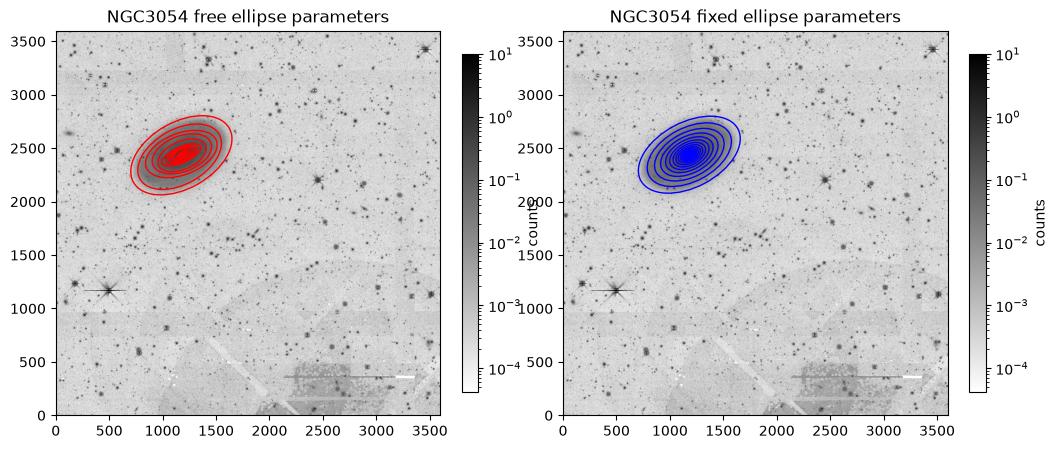

In [92]:
#this will do the fitting of the isophotes by making an instance of the Ellipse class
#It then fits the data using the initial guesses we computed above
galname = 'NGC3054'
ellipse[galname] = Ellipse(data[galname], geometry[galname])
isolist[galname] = ellipse[galname].fit_image()

#save the shape values of the average ellipse.  
xcenav[galname], ycenav[galname], epsav[galname], paav[galname] = plotaper(galname, data[galname],isolist[galname],44.5)

v1 =  0.00, v2 = 10.00


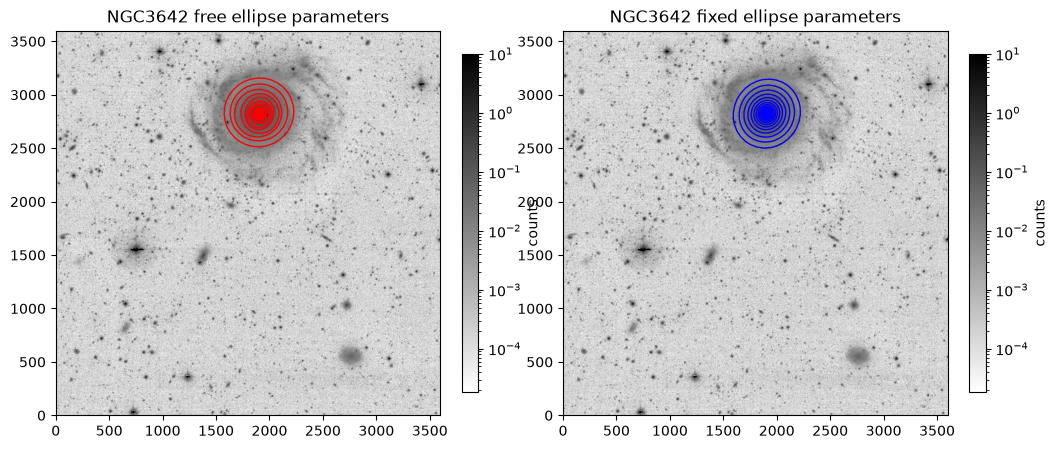

In [121]:
#this will do the fitting of the isophotes by making an instance of the Ellipse class
#It then fits the data using the initial guesses we computed above
galname = 'NGC3642'
ellipse[galname] = Ellipse(data[galname], geometry[galname])
isolist[galname] = ellipse[galname].fit_image()

#save the shape values of the average ellipse.  
xcenav[galname], ycenav[galname], epsav[galname], paav[galname] = plotaper(galname, data[galname],isolist[galname],43)

NGC 3642 resists ellispe fitting, this is the best result I could get. I could not get the program to go all the way out to the pseudoring. 

v1 =  0.00, v2 = 10.00


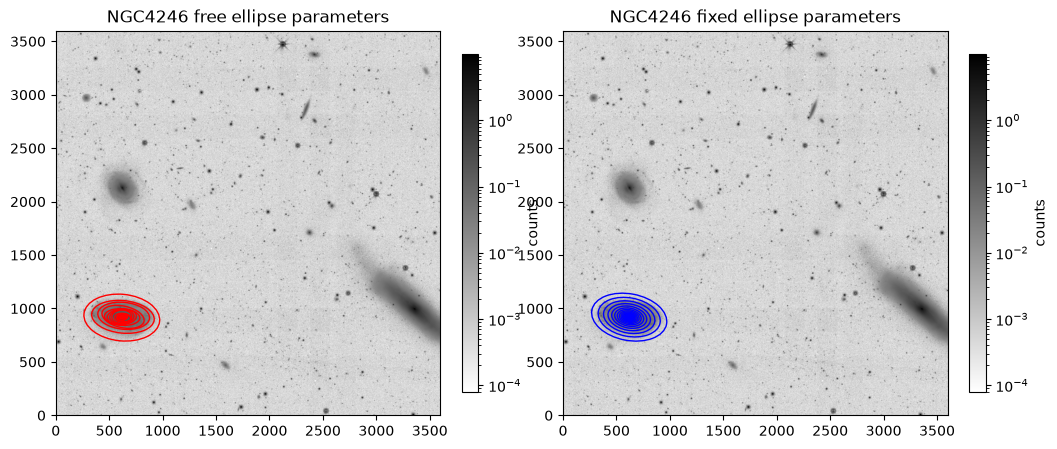

In [94]:
#this will do the fitting of the isophotes by making an instance of the Ellipse class
#It then fits the data using the initial guesses we computed above
galname = 'NGC4246'
ellipse[galname] = Ellipse(data[galname], geometry[galname])
isolist[galname] = ellipse[galname].fit_image()

#save the shape values of the average ellipse.  
xcenav[galname], ycenav[galname], epsav[galname], paav[galname] = plotaper(galname, data[galname],isolist[galname],46.5)

v1 =  0.00, v2 = 10.00


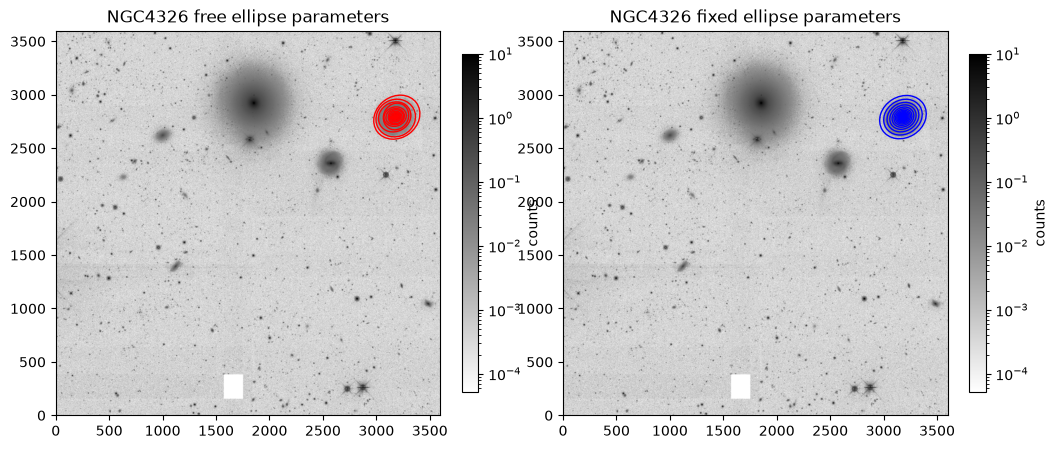

In [95]:
#this will do the fitting of the isophotes by making an instance of the Ellipse class
#It then fits the data using the initial guesses we computed above
galname = 'NGC4326'
ellipse[galname] = Ellipse(data[galname], geometry[galname])
isolist[galname] = ellipse[galname].fit_image()

#save the shape values of the average ellipse.  
xcenav[galname], ycenav[galname], epsav[galname], paav[galname] = plotaper(galname, data[galname],isolist[galname],45.5)

v1 =  0.00, v2 = 10.00


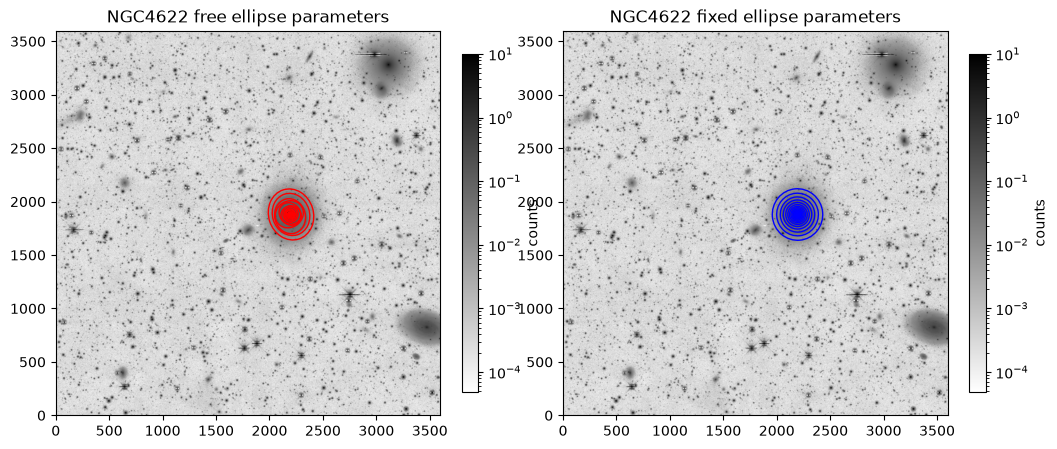

In [110]:
#this will do the fitting of the isophotes by making an instance of the Ellipse class
#It then fits the data using the initial guesses we computed above
galname = 'NGC4622'
ellipse[galname] = Ellipse(data[galname], geometry[galname])
isolist[galname] = ellipse[galname].fit_image()

#save the shape values of the average ellipse.  
xcenav[galname], ycenav[galname], epsav[galname], paav[galname] = plotaper(galname, data[galname],isolist[galname],42)

This section involves making free and fixed-ellipse parameters for our galaxies. The fixed parameters are more "symmetric" with each other than the free ellipse paramaters, as the latter has a tendency to contain overlapping ellipses. 

This one also was a bit tricky to fit. This is the best result I could get. 

In [122]:
from photutils.aperture import ApertureStats
from photutils.aperture import EllipticalAnnulus, EllipticalAperture

#initialize dictionary for half-light radii
rhalfasec = {}

In [134]:
def LS(x, y): ## least squares function from PHSX 315

  xBar = 0 ## calculate xBar:

  for i in range(0,len(x)):
    xBar += x[i]

  xBar = xBar / len(x)


  yBar = 0 ## calculate yBar:

  for i in range(0,len(y)):
    yBar += y[i]

  yBar = yBar / len(y)


  xSqrdBar = 0 ## calculating xSqrdBar:

  for i in range(0, len(x)):
    xSqrdBar += x[i]**2

  xSqrdBar = xSqrdBar / len(x)


  xyBar = 0 ## calculating xyBar:

  for i in range(0,len(x)):
    xyBar += x[i]*y[i]

  xyBar = xyBar / len(x)


  ## calculating a and b:
  a = (xyBar - xBar*yBar) / (xSqrdBar - xBar**2)
  b = (xSqrdBar*yBar - xBar*xyBar) / (xSqrdBar - xBar**2)


  ## uncertainty:


  deltaSqrdBar = 0 ## calculating deltaSqrdBar:

  for i in range(0, len(x)): ## sum
    deltaSqrdBar += ( y[i] - (a*x[i] + b) )**2

  deltaSqrdBar = deltaSqrdBar / len(x)

  delA = ( deltaSqrdBar / ( ( len(x)-2 )*( xSqrdBar - xBar**2 ) ) )**(0.5)
  delB = ( (deltaSqrdBar*xSqrdBar) / ( ( len(x)-2 )*( xSqrdBar - xBar**2 ) ) )**(0.5)

  ## calculating R^2

  top = 0
  for i in range(0, len(x)): ## sum
    top += ( y[i] - (a*x[i] + b) )**2

  bottom = 0
  for i in range(0, len(x)): ## sum
    bottom += ( y[i] - yBar )**2

  RSqrd = 1 - top / bottom


  return a, b, delA, delB, RSqrd ## y = ax +b

Central disk brightness: 17.949 +- 0.039
the half-light radius = 45.000 [asec]
Surface brightness near center:  14.571942717144594
Surface brightness near the effective radius:  18.775743185182165
isophote index that is closest to the half-light radius:  60
flux_SB(rhalf) / flux_SB(rcent) = 237.117 +- 2.846
Counts scale range:
4.1706765623530364e-05 10.000043869018555


Text(0.5, 1.0, 'NGC3054 - Half-Light Radius')

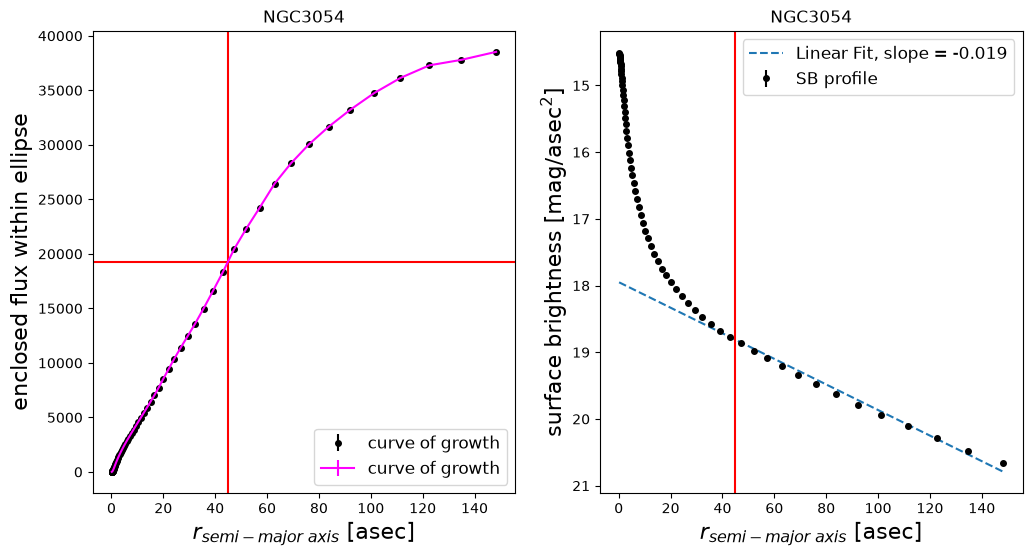

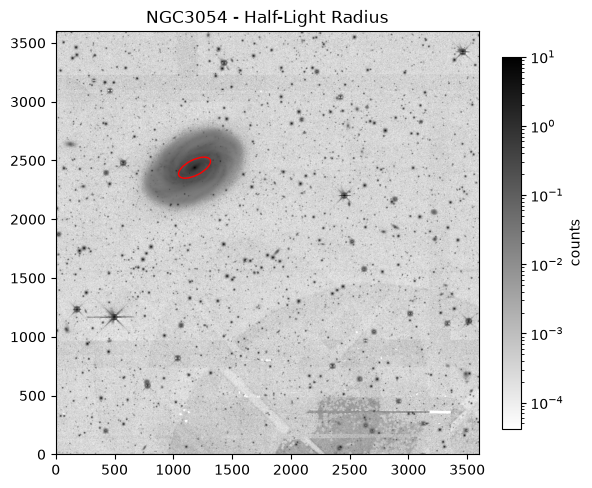

In [142]:
galname = 'NGC3054'

#we will use the isophote shape that corresponds to the average isophote values from the previous section
#xcenav[galname], ycenav[galname], epsav[galname], paav[galname]

#the magnitude zeropoint of the image, such that mag = -2.5 * log(flux) + magzp
magzp = header[galname]['MAGZERO']

#The pixel scale from the header converted from degrees to asec
pixscale = header[galname]['CD2_2'] * 3600.    #in asec/pix

#Go through every aperture and measure the surface brightness between it and the next most outer isophote
#initialize arrays for surface brightness and bin center
rcent = np.array([])
sbcent = np.array([])
sbcent_err = np.array([])
totflux = np.array([])
totflux_err = np.array([])
for aindx, a_out in enumerate(isolist[galname].sma):

    #skip the first isophote because I will always compute the values between the current isophote and the previous
    if aindx==0:
        a_in = 0.01

    if aindx>0:
        #create the inner and outer minor axes from the major axes and ellipticity
        b_out = a_out * (1.-epsav[galname])
        b_in = a_in * (1.-epsav[galname])

        #print(f'a_out = {a_out:.2f}; a_in ={a_in:.2f}; b_out ={b_out:.2f}; b_in ={b_in:.2f}')
        #set up elliptical annulus using parameters at rhalf
        annulus_aperture = EllipticalAnnulus((xcenav[galname],ycenav[galname]), 
                                             a_in, a_out, b_out, b_in = b_in,
                                             theta = paav[galname])
        total_aperture = EllipticalAperture((xcenav[galname],ycenav[galname]), 
                                             a_out, b_out, theta = paav[galname])
        aperstats_ann = ApertureStats(data[galname],annulus_aperture)
        aperstats_tot = ApertureStats(data[galname],total_aperture)
        a_in = a_out

        #the central radius of each annulus in asec.  I'm appending each central radius to the existing array
        rcent = np.append(rcent, (a_in + a_out) / 2.*pixscale)
        #the average pixel flux within each annulus
        avflux = aperstats_ann.mean
        #the standard deviation of the pixel values within each annulus
        stdflux = aperstats_ann.std
        #the number of pixels in each annulus
        numpix = aperstats_ann.sum_aper_area

        #Now do the total within each aperture
        totflux = np.append(totflux,aperstats_tot.sum)
        totflux_err = np.append(totflux_err,aperstats_tot.std)
        
        #****************************
        #your code here
        #the area of a pixel
        pixarea = pixscale**2 ## gives a result in asec^2 / pix^2
        
        #determine the average surface brightness in mag/asec^2.

        #totMag = -2.5 * log(totflux) + magzp # flux adds linearly, magnitudes do not. 
        totMag = -2.5 * np.log10(totflux[aindx-1]) + magzp ## index minus one since the loop index and the array index are ofset by one. 
        
        #avMag = totMag + 2.5log10(A) where A is the area of the annulus
        surfaceArea = pixarea * numpix ## surface area of annulus
        surfaceArea = surfaceArea / u.pix 
        surfaceArea = surfaceArea / u.pix ## fixing units 
        avMag = totMag + 2.5 * np.log10( surfaceArea ) 
        
        #avFluxErr = sqrt( (partial avMag / partial total flux * total flux error)**2 ), partial avMag / partial total flux = -2.5 / ( totflux * np.log(10)) # the partial derivative of log_10(x) = 1/(x * ln(x)) by change of base formula for logs
        
        #avMag = avMag * u.pix #* u.pix ## doing this for the same reason as for avflux_err
        sbcent = np.append(sbcent, avMag)
        # the uncertainty in the mean flux (this is not the standard deviation of all the pixels in the aperture).  
        # Check back to Homework 1
        avflux_err = np.sqrt( ( ( totflux_err[aindx-1] * -2.5 ) / ( totflux[aindx-1] * np.log(10) ) )**2 ) ## again adjusting the index as with the definition of totMag
        avflux_err = avflux_err #* u.pix  * u.pix #this gets rid of the units on the flux error so that the next part works
        sbcent_err = np.append(sbcent_err, avflux_err)

fig,ax = plt.subplots(1,2,figsize=(12, 6))

#plot the semi-major axis vs. magnitude
ax[1].errorbar(rcent, sbcent, yerr=sbcent_err, 
             fmt='o', markersize=4, color='black', label='SB profile')

## begin disk / bulge profile fitting: 
model_x = rcent[-1-17:] #eyeballing this 
model_y = sbcent[-1-17:]
fit = LS(model_x, model_y)
slopeLabel = f'Linear Fit, slope = -{fit[0]:.3f}'
ax[1].plot([rcent[0], rcent[-1]], [fit[0] * rcent[0] + fit[1],  fit[0] * rcent[-1] + fit[1] ], '--', label= slopeLabel)
print(f'Central disk brightness: {fit[1]:.3f} +- {fit[3]:.3f}')

## end disk / bulge profile fitting: 

ax[1].invert_yaxis()

ax[1].legend(fontsize=12)

ax[1].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[1].set_ylabel('surface brightness [mag/asec$^2$]',fontsize=16)
ax[1].set_title(galname)

#plot the curve of growth
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='o', markersize=4, color='black', label='curve of growth')
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='-', markersize=4, color='magenta', label='curve of growth')

#ax[0].axvline(rhalfasec[galname], color='red', label='$r_{half}$')
ax[0].legend(fontsize=12)

ax[0].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[0].set_ylabel('enclosed flux within ellipse',fontsize=16)
ax[0].set_title(galname)

#measure the half-light radius
#a horizontal line at half the total flux
ax[0].axhline(totflux[-1]/2., color='red')

#a vertical line at half the total flux
#*************************
#You will need to adjust rhalfpix by eye to get the radius that encompasses half the light.
#you shoul do this using the plot you make, not using the image itself.
rhalfasec[galname] = 45
ax[0].axvline(rhalfasec[galname], color='red')
print(f'the half-light radius = {rhalfasec[galname]:.3f} [asec]')

#plot the same line on the surface brightness plot
ax[1].axvline(rhalfasec[galname], color='red', label='$r_{half}$')

#calculate and print the surface brightness somewhere within 3 arcsec from the center.  
#Note that some of the inner values have NaNs because the isophote fitting failed there.  
#Just keep going out in index until you get a valid value
#***********************
#your code here
centerIndex = 11 ## for ease of use
#print(sbcent[centerIndex:centerIndex+10])
print(f'Surface brightness near center: ',sbcent[centerIndex]) 


#calculate and print out the surface brightness at the effective radius
#***********************
#your code here
#print('rcent length: ', len(rcent))
#print('rcent[52] : ',rcent[52]) ## finding the right index... 
halfRadIndex = 60
print('Surface brightness near the effective radius: ', sbcent[halfRadIndex] )

#find the isophote that best corresponds to the half-light radius
#We will do this by computing the difference between the half-light radius
#and the semi-major axis of each isophote.  
diff = rcent - rhalfasec[galname]

#this returns the index of the isophote that is closes to the half-light radius
#We use this to set the ellipticity and PA of the isophotes
rhalfasecind = np.argmin(abs(diff))


#
print('isophote index that is closest to the half-light radius: ', rhalfasecind)

#calculate and print out the ratio of the **flux** surface brightness between the center and at r_half
#***********************
#your code here
flux_rat = totflux[halfRadIndex] / totflux[centerIndex]

## calculate uncertanity: flux_rat_err = sqrt( ( partial ratio / partial flux_SB(rhalf) * flux_SB(rhalf)_err )**2 + ( partial ratio / partial flux_SB(rcent) * flux_SB(rcent)_err )**2 )

## partial ratio / partial flux_SB(rhalf) = 1 / flux_SB(rcent)
par_f_half = 1 / totflux[halfRadIndex]

## partial ratio / partial flux_SB(rcent) = -flux_SB(rhalf) / (flux_SB(rcent))**2
par_f_cent = -totflux[halfRadIndex] / ( totflux[centerIndex] )**2

ratio_uncert = np.sqrt( ( par_f_half * totflux_err[halfRadIndex] )**2 + ( par_f_cent * totflux_err[centerIndex] )**2 )

#print('length of totflux: ', len(totflux))
print(f'flux_SB(rhalf) / flux_SB(rcent) = {flux_rat:.3f} +- {ratio_uncert:.3f}')

# plotting the isophote over the image: 
print('Counts scale range:') ## print to make the output look a bit less cluttered
## taking some code from cell [75] and using it to plot only one isophote:
fig,ax = imdisplay(data[galname], 44.5, 99.99, logscale=True) ## plotting the image

aperiter = EllipticalAperture((isolist[galname].x0[rhalfasecind], isolist[galname].y0[rhalfasecind]), isolist[galname].sma[rhalfasecind], 
                                      isolist[galname].sma[rhalfasecind] * (1-isolist[galname].eps[rhalfasecind]), isolist[galname].pa[rhalfasecind]) ## grabbing the correct isophote
aperiter.plot(ax,color='red') # plotting the isophote 
ax.set_title(galname+" - Half-Light Radius")
    
        



Central disk brightness: 17.642 +- 0.071
the half-light radius = 24.000 [asec]
Surface brightness near center:  15.079505207888127
Surface brightness near the effective radius:  18.39901425607768
isophote index that is closest to the half-light radius:  55
flux_SB(rhalf) / flux_SB(rcent) = 647.836 +- 6.373
Counts scale range:
1.8366183503531076e-05 10.00002670288086


Text(0.5, 1.0, 'NGC3642 - Half-Light Radius')

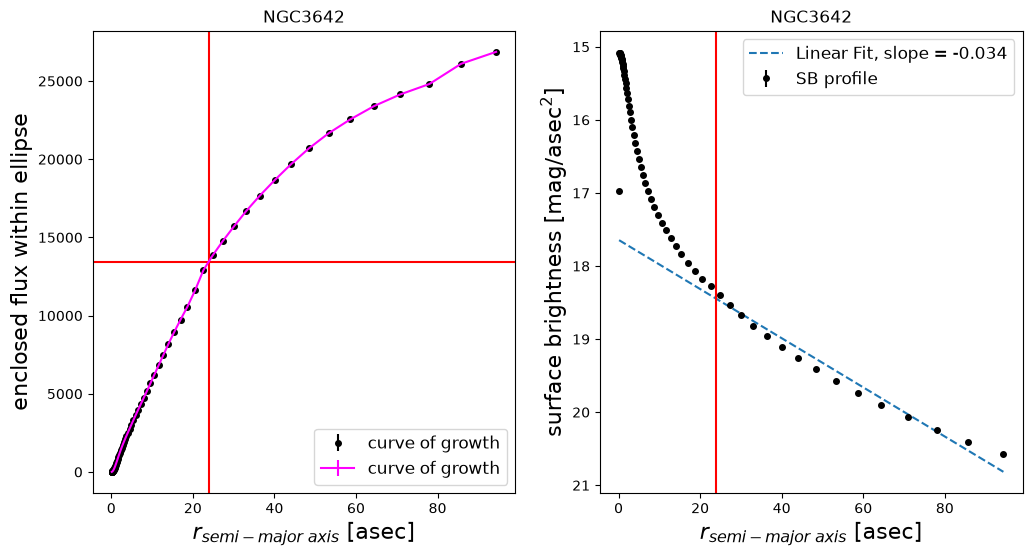

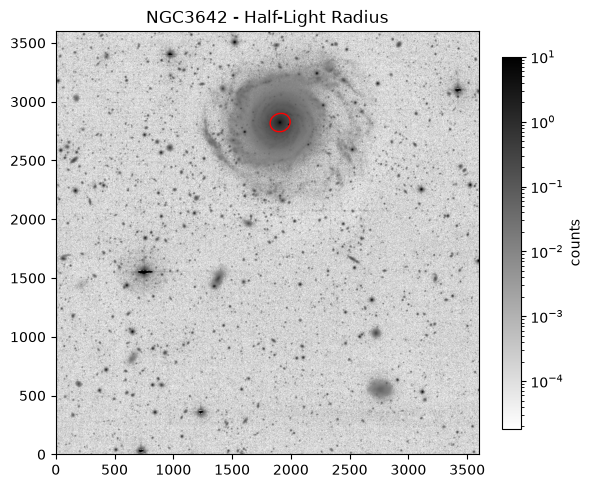

In [143]:
galname = 'NGC3642'

#we will use the isophote shape that corresponds to the average isophote values from the previous section
#xcenav[galname], ycenav[galname], epsav[galname], paav[galname]

#the magnitude zeropoint of the image, such that mag = -2.5 * log(flux) + magzp
magzp = header[galname]['MAGZERO']

#The pixel scale from the header converted from degrees to asec
pixscale = header[galname]['CD2_2'] * 3600.    #in asec/pix

#Go through every aperture and measure the surface brightness between it and the next most outer isophote
#initialize arrays for surface brightness and bin center
rcent = np.array([])
sbcent = np.array([])
sbcent_err = np.array([])
totflux = np.array([])
totflux_err = np.array([])
for aindx, a_out in enumerate(isolist[galname].sma):

    #skip the first isophote because I will always compute the values between the current isophote and the previous
    if aindx==0:
        a_in = 0.01

    if aindx>0:
        #create the inner and outer minor axes from the major axes and ellipticity
        b_out = a_out * (1.-epsav[galname])
        b_in = a_in * (1.-epsav[galname])

        #print(f'a_out = {a_out:.2f}; a_in ={a_in:.2f}; b_out ={b_out:.2f}; b_in ={b_in:.2f}')
        #set up elliptical annulus using parameters at rhalf
        annulus_aperture = EllipticalAnnulus((xcenav[galname],ycenav[galname]), 
                                             a_in, a_out, b_out, b_in = b_in,
                                             theta = paav[galname])
        total_aperture = EllipticalAperture((xcenav[galname],ycenav[galname]), 
                                             a_out, b_out, theta = paav[galname])
        aperstats_ann = ApertureStats(data[galname],annulus_aperture)
        aperstats_tot = ApertureStats(data[galname],total_aperture)
        a_in = a_out

        #the central radius of each annulus in asec.  I'm appending each central radius to the existing array
        rcent = np.append(rcent, (a_in + a_out) / 2.*pixscale)
        #the average pixel flux within each annulus
        avflux = aperstats_ann.mean
        #the standard deviation of the pixel values within each annulus
        stdflux = aperstats_ann.std
        #the number of pixels in each annulus
        numpix = aperstats_ann.sum_aper_area

        #Now do the total within each aperture
        totflux = np.append(totflux,aperstats_tot.sum)
        totflux_err = np.append(totflux_err,aperstats_tot.std)
        
        #****************************
        #your code here
        #the area of a pixel
        pixarea = pixscale**2 ## gives a result in asec^2 / pix^2
        
        #determine the average surface brightness in mag/asec^2.

        #totMag = -2.5 * log(totflux) + magzp # flux adds linearly, magnitudes do not. 
        totMag = -2.5 * np.log10(totflux[aindx-1]) + magzp ## index minus one since the loop index and the array index are ofset by one. 
        
        #avMag = totMag + 2.5log10(A) where A is the area of the annulus
        surfaceArea = pixarea * numpix ## surface area of annulus
        surfaceArea = surfaceArea / u.pix 
        surfaceArea = surfaceArea / u.pix ## fixing units 
        avMag = totMag + 2.5 * np.log10( surfaceArea ) 
        
        #avFluxErr = sqrt( (partial avMag / partial total flux * total flux error)**2 ), partial avMag / partial total flux = -2.5 / ( totflux * np.log(10)) # the partial derivative of log_10(x) = 1/(x * ln(x)) by change of base formula for logs
        
        #avMag = avMag * u.pix #* u.pix ## doing this for the same reason as for avflux_err
        sbcent = np.append(sbcent, avMag)
        # the uncertainty in the mean flux (this is not the standard deviation of all the pixels in the aperture).  
        # Check back to Homework 1
        avflux_err = np.sqrt( ( ( totflux_err[aindx-1] * -2.5 ) / ( totflux[aindx-1] * np.log(10) ) )**2 ) ## again adjusting the index as with the definition of totMag
        avflux_err = avflux_err #* u.pix  * u.pix #this gets rid of the units on the flux error so that the next part works
        sbcent_err = np.append(sbcent_err, avflux_err)

fig,ax = plt.subplots(1,2,figsize=(12, 6))

#plot the semi-major axis vs. magnitude
ax[1].errorbar(rcent, sbcent, yerr=sbcent_err, 
             fmt='o', markersize=4, color='black', label='SB profile')

## begin disk / bulge profile fitting: 
model_x = rcent[-1-17:] #eyeballing this 
model_y = sbcent[-1-17:]
fit = LS(model_x, model_y)
slopeLabel = f'Linear Fit, slope = -{fit[0]:.3f}'
ax[1].plot([rcent[0], rcent[-1]], [fit[0] * rcent[0] + fit[1],  fit[0] * rcent[-1] + fit[1] ], '--', label= slopeLabel)
print(f'Central disk brightness: {fit[1]:.3f} +- {fit[3]:.3f}')

## end disk / bulge profile fitting: 

ax[1].invert_yaxis()

ax[1].legend(fontsize=12)

ax[1].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[1].set_ylabel('surface brightness [mag/asec$^2$]',fontsize=16)
ax[1].set_title(galname)

#plot the curve of growth
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='o', markersize=4, color='black', label='curve of growth')
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='-', markersize=4, color='magenta', label='curve of growth')

#ax[0].axvline(rhalfasec[galname], color='red', label='$r_{half}$')
ax[0].legend(fontsize=12)

ax[0].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[0].set_ylabel('enclosed flux within ellipse',fontsize=16)
ax[0].set_title(galname)

#measure the half-light radius
#a horizontal line at half the total flux
ax[0].axhline(totflux[-1]/2., color='red')

#a vertical line at half the total flux
#*************************
#You will need to adjust rhalfpix by eye to get the radius that encompasses half the light.
#you shoul do this using the plot you make, not using the image itself.
rhalfasec[galname] = 24
ax[0].axvline(rhalfasec[galname], color='red')
print(f'the half-light radius = {rhalfasec[galname]:.3f} [asec]')

#plot the same line on the surface brightness plot
ax[1].axvline(rhalfasec[galname], color='red', label='$r_{half}$')

#calculate and print the surface brightness somewhere within 3 arcsec from the center.  
#Note that some of the inner values have NaNs because the isophote fitting failed there.  
#Just keep going out in index until you get a valid value
#***********************
#your code here
centerIndex = 5 ## for ease of use
#print(sbcent[centerIndex:centerIndex+10])
print(f'Surface brightness near center: ',sbcent[centerIndex]) 


#calculate and print out the surface brightness at the effective radius
#***********************
#your code here
#print('rcent length: ', len(rcent))
#print('rcent[52] : ',rcent[52]) ## finding the right index... 
halfRadIndex = 55
print('Surface brightness near the effective radius: ', sbcent[halfRadIndex] )

#find the isophote that best corresponds to the half-light radius
#We will do this by computing the difference between the half-light radius
#and the semi-major axis of each isophote.  
diff = rcent - rhalfasec[galname]

#this returns the index of the isophote that is closes to the half-light radius
#We use this to set the ellipticity and PA of the isophotes
rhalfasecind = np.argmin(abs(diff))


#
print('isophote index that is closest to the half-light radius: ', rhalfasecind)

#calculate and print out the ratio of the **flux** surface brightness between the center and at r_half
#***********************
#your code here
flux_rat = totflux[halfRadIndex] / totflux[centerIndex]

## calculate uncertanity: flux_rat_err = sqrt( ( partial ratio / partial flux_SB(rhalf) * flux_SB(rhalf)_err )**2 + ( partial ratio / partial flux_SB(rcent) * flux_SB(rcent)_err )**2 )

## partial ratio / partial flux_SB(rhalf) = 1 / flux_SB(rcent)
par_f_half = 1 / totflux[halfRadIndex]

## partial ratio / partial flux_SB(rcent) = -flux_SB(rhalf) / (flux_SB(rcent))**2
par_f_cent = -totflux[halfRadIndex] / ( totflux[centerIndex] )**2

ratio_uncert = np.sqrt( ( par_f_half * totflux_err[halfRadIndex] )**2 + ( par_f_cent * totflux_err[centerIndex] )**2 )

#print('length of totflux: ', len(totflux))
print(f'flux_SB(rhalf) / flux_SB(rcent) = {flux_rat:.3f} +- {ratio_uncert:.3f}')

# plotting the isophote over the image: 
print('Counts scale range:') ## print to make the output look a bit less cluttered
## taking some code from cell [75] and using it to plot only one isophote:
fig,ax = imdisplay(data[galname], 43, 99.99, logscale=True) ## plotting the image

aperiter = EllipticalAperture((isolist[galname].x0[rhalfasecind], isolist[galname].y0[rhalfasecind]), isolist[galname].sma[rhalfasecind], 
                                      isolist[galname].sma[rhalfasecind] * (1-isolist[galname].eps[rhalfasecind]), isolist[galname].pa[rhalfasecind]) ## grabbing the correct isophote
aperiter.plot(ax,color='red') # plotting the isophote 
ax.set_title(galname+" - Half-Light Radius")
    
        



Central disk brightness: 18.664 +- 0.022
the half-light radius = 30.500 [asec]
Surface brightness near center:  17.373222332494613
Surface brightness near the effective radius:  19.45724610794207
isophote index that is closest to the half-light radius:  56
flux_SB(rhalf) / flux_SB(rcent) = 2021.431 +- 17.380
Counts scale range:
7.906777726020666e-05 9.999992370605469


Text(0.5, 1.0, 'NGC4246 - Half-Light Radius')

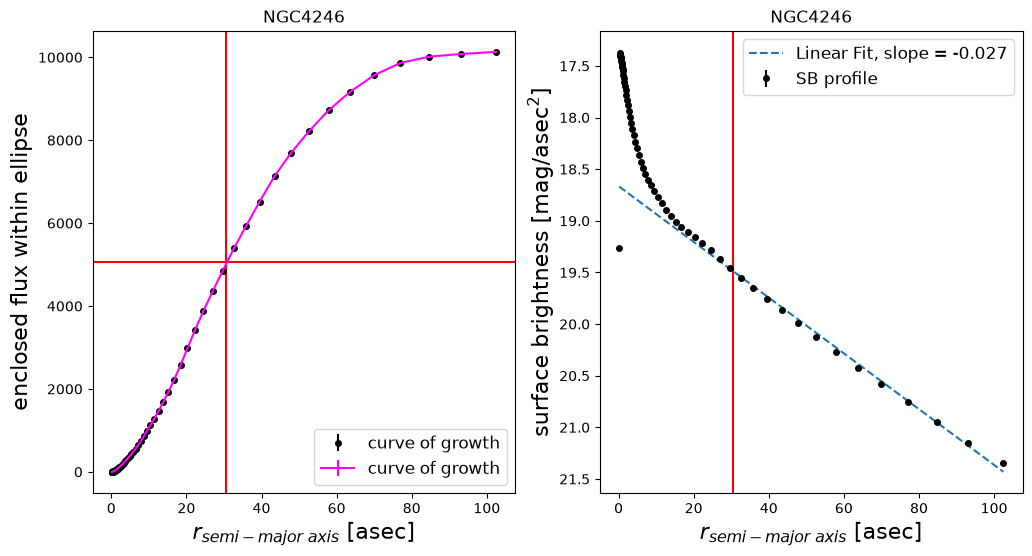

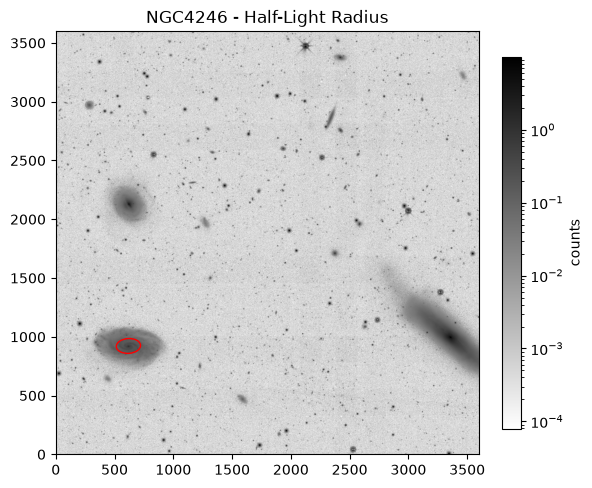

In [149]:
galname = 'NGC4246'

#we will use the isophote shape that corresponds to the average isophote values from the previous section
#xcenav[galname], ycenav[galname], epsav[galname], paav[galname]

#the magnitude zeropoint of the image, such that mag = -2.5 * log(flux) + magzp
magzp = header[galname]['MAGZERO']

#The pixel scale from the header converted from degrees to asec
pixscale = header[galname]['CD2_2'] * 3600.    #in asec/pix

#Go through every aperture and measure the surface brightness between it and the next most outer isophote
#initialize arrays for surface brightness and bin center
rcent = np.array([])
sbcent = np.array([])
sbcent_err = np.array([])
totflux = np.array([])
totflux_err = np.array([])
for aindx, a_out in enumerate(isolist[galname].sma):

    #skip the first isophote because I will always compute the values between the current isophote and the previous
    if aindx==0:
        a_in = 0.01

    if aindx>0:
        #create the inner and outer minor axes from the major axes and ellipticity
        b_out = a_out * (1.-epsav[galname])
        b_in = a_in * (1.-epsav[galname])

        #print(f'a_out = {a_out:.2f}; a_in ={a_in:.2f}; b_out ={b_out:.2f}; b_in ={b_in:.2f}')
        #set up elliptical annulus using parameters at rhalf
        annulus_aperture = EllipticalAnnulus((xcenav[galname],ycenav[galname]), 
                                             a_in, a_out, b_out, b_in = b_in,
                                             theta = paav[galname])
        total_aperture = EllipticalAperture((xcenav[galname],ycenav[galname]), 
                                             a_out, b_out, theta = paav[galname])
        aperstats_ann = ApertureStats(data[galname],annulus_aperture)
        aperstats_tot = ApertureStats(data[galname],total_aperture)
        a_in = a_out

        #the central radius of each annulus in asec.  I'm appending each central radius to the existing array
        rcent = np.append(rcent, (a_in + a_out) / 2.*pixscale)
        #the average pixel flux within each annulus
        avflux = aperstats_ann.mean
        #the standard deviation of the pixel values within each annulus
        stdflux = aperstats_ann.std
        #the number of pixels in each annulus
        numpix = aperstats_ann.sum_aper_area

        #Now do the total within each aperture
        totflux = np.append(totflux,aperstats_tot.sum)
        totflux_err = np.append(totflux_err,aperstats_tot.std)
        
        #****************************
        #your code here
        #the area of a pixel
        pixarea = pixscale**2 ## gives a result in asec^2 / pix^2
        
        #determine the average surface brightness in mag/asec^2.

        #totMag = -2.5 * log(totflux) + magzp # flux adds linearly, magnitudes do not. 
        totMag = -2.5 * np.log10(totflux[aindx-1]) + magzp ## index minus one since the loop index and the array index are ofset by one. 
        
        #avMag = totMag + 2.5log10(A) where A is the area of the annulus
        surfaceArea = pixarea * numpix ## surface area of annulus
        surfaceArea = surfaceArea / u.pix 
        surfaceArea = surfaceArea / u.pix ## fixing units 
        avMag = totMag + 2.5 * np.log10( surfaceArea ) 
        
        #avFluxErr = sqrt( (partial avMag / partial total flux * total flux error)**2 ), partial avMag / partial total flux = -2.5 / ( totflux * np.log(10)) # the partial derivative of log_10(x) = 1/(x * ln(x)) by change of base formula for logs
        
        #avMag = avMag * u.pix #* u.pix ## doing this for the same reason as for avflux_err
        sbcent = np.append(sbcent, avMag)
        # the uncertainty in the mean flux (this is not the standard deviation of all the pixels in the aperture).  
        # Check back to Homework 1
        avflux_err = np.sqrt( ( ( totflux_err[aindx-1] * -2.5 ) / ( totflux[aindx-1] * np.log(10) ) )**2 ) ## again adjusting the index as with the definition of totMag
        avflux_err = avflux_err #* u.pix  * u.pix #this gets rid of the units on the flux error so that the next part works
        sbcent_err = np.append(sbcent_err, avflux_err)

fig,ax = plt.subplots(1,2,figsize=(12, 6))

#plot the semi-major axis vs. magnitude
ax[1].errorbar(rcent, sbcent, yerr=sbcent_err, 
             fmt='o', markersize=4, color='black', label='SB profile')

## begin disk / bulge profile fitting: 
model_x = rcent[-1-17:] #eyeballing this 
model_y = sbcent[-1-17:]
fit = LS(model_x, model_y)
slopeLabel = f'Linear Fit, slope = -{fit[0]:.3f}'
ax[1].plot([rcent[0], rcent[-1]], [fit[0] * rcent[0] + fit[1],  fit[0] * rcent[-1] + fit[1] ], '--', label= slopeLabel)
print(f'Central disk brightness: {fit[1]:.3f} +- {fit[3]:.3f}')

## end disk / bulge profile fitting: 

ax[1].invert_yaxis()

ax[1].legend(fontsize=12)

ax[1].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[1].set_ylabel('surface brightness [mag/asec$^2$]',fontsize=16)
ax[1].set_title(galname)

#plot the curve of growth
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='o', markersize=4, color='black', label='curve of growth')
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='-', markersize=4, color='magenta', label='curve of growth')

#ax[0].axvline(rhalfasec[galname], color='red', label='$r_{half}$')
ax[0].legend(fontsize=12)

ax[0].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[0].set_ylabel('enclosed flux within ellipse',fontsize=16)
ax[0].set_title(galname)

#measure the half-light radius
#a horizontal line at half the total flux
ax[0].axhline(totflux[-1]/2., color='red')

#a vertical line at half the total flux
#*************************
#You will need to adjust rhalfpix by eye to get the radius that encompasses half the light.
#you shoul do this using the plot you make, not using the image itself.
rhalfasec[galname] = 30.5
ax[0].axvline(rhalfasec[galname], color='red')
print(f'the half-light radius = {rhalfasec[galname]:.3f} [asec]')

#plot the same line on the surface brightness plot
ax[1].axvline(rhalfasec[galname], color='red', label='$r_{half}$')

#calculate and print the surface brightness somewhere within 3 arcsec from the center.  
#Note that some of the inner values have NaNs because the isophote fitting failed there.  
#Just keep going out in index until you get a valid value
#***********************
#your code here
centerIndex = 6 ## for ease of use
#print(sbcent[centerIndex:centerIndex+10])
print(f'Surface brightness near center: ',sbcent[centerIndex]) 


#calculate and print out the surface brightness at the effective radius
#***********************
#your code here
#print('rcent length: ', len(rcent))
#print('rcent[52] : ',rcent[52]) ## finding the right index... 
halfRadIndex = 56
print('Surface brightness near the effective radius: ', sbcent[halfRadIndex] )

#find the isophote that best corresponds to the half-light radius
#We will do this by computing the difference between the half-light radius
#and the semi-major axis of each isophote.  
diff = rcent - rhalfasec[galname]

#this returns the index of the isophote that is closes to the half-light radius
#We use this to set the ellipticity and PA of the isophotes
rhalfasecind = np.argmin(abs(diff))


#
print('isophote index that is closest to the half-light radius: ', rhalfasecind)

#calculate and print out the ratio of the **flux** surface brightness between the center and at r_half
#***********************
#your code here
flux_rat = totflux[halfRadIndex] / totflux[centerIndex]

## calculate uncertanity: flux_rat_err = sqrt( ( partial ratio / partial flux_SB(rhalf) * flux_SB(rhalf)_err )**2 + ( partial ratio / partial flux_SB(rcent) * flux_SB(rcent)_err )**2 )

## partial ratio / partial flux_SB(rhalf) = 1 / flux_SB(rcent)
par_f_half = 1 / totflux[halfRadIndex]

## partial ratio / partial flux_SB(rcent) = -flux_SB(rhalf) / (flux_SB(rcent))**2
par_f_cent = -totflux[halfRadIndex] / ( totflux[centerIndex] )**2

ratio_uncert = np.sqrt( ( par_f_half * totflux_err[halfRadIndex] )**2 + ( par_f_cent * totflux_err[centerIndex] )**2 )

#print('length of totflux: ', len(totflux))
print(f'flux_SB(rhalf) / flux_SB(rcent) = {flux_rat:.3f} +- {ratio_uncert:.3f}')

# plotting the isophote over the image: 
print('Counts scale range:') ## print to make the output look a bit less cluttered
## taking some code from cell [75] and using it to plot only one isophote:
fig,ax = imdisplay(data[galname], 46.5, 99.99, logscale=True) ## plotting the image

aperiter = EllipticalAperture((isolist[galname].x0[rhalfasecind], isolist[galname].y0[rhalfasecind]), isolist[galname].sma[rhalfasecind], 
                                      isolist[galname].sma[rhalfasecind] * (1-isolist[galname].eps[rhalfasecind]), isolist[galname].pa[rhalfasecind]) ## grabbing the correct isophote
aperiter.plot(ax,color='red') # plotting the isophote 
ax.set_title(galname+" - Half-Light Radius")
    
        



Central disk brightness: 18.819 +- 0.045
the half-light radius = 14.500 [asec]
Surface brightness near center:  15.037300605025607
Surface brightness near the effective radius:  18.824326712619545
isophote index that is closest to the half-light radius:  49
flux_SB(rhalf) / flux_SB(rcent) = 91.659 +- 1.335
Counts scale range:
5.162178887985636e-05 10.000020980834961


Text(0.5, 1.0, 'NGC4326 - Half-Light Radius')

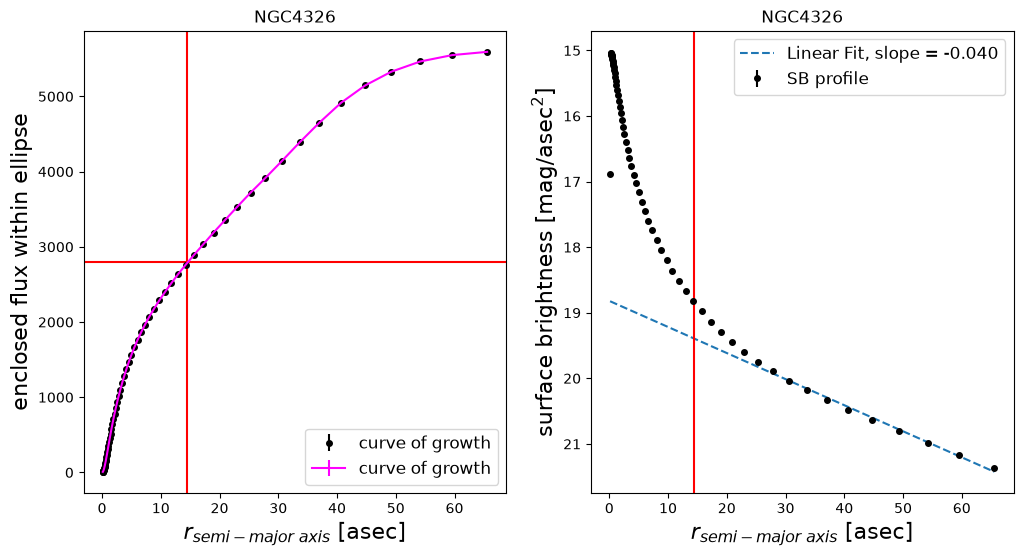

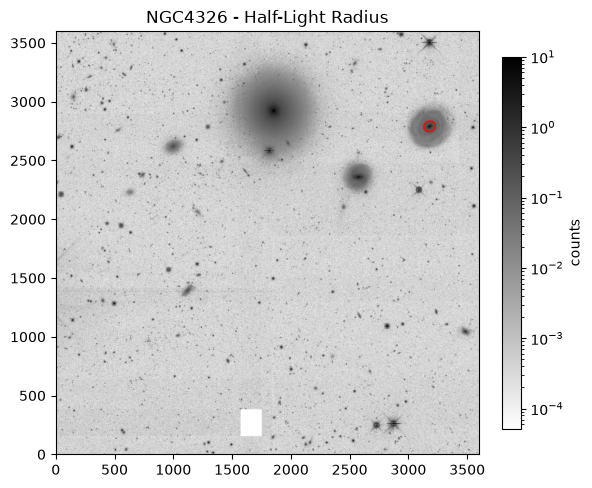

In [157]:
galname = 'NGC4326'

#we will use the isophote shape that corresponds to the average isophote values from the previous section
#xcenav[galname], ycenav[galname], epsav[galname], paav[galname]

#the magnitude zeropoint of the image, such that mag = -2.5 * log(flux) + magzp
magzp = header[galname]['MAGZERO']

#The pixel scale from the header converted from degrees to asec
pixscale = header[galname]['CD2_2'] * 3600.    #in asec/pix

#Go through every aperture and measure the surface brightness between it and the next most outer isophote
#initialize arrays for surface brightness and bin center
rcent = np.array([])
sbcent = np.array([])
sbcent_err = np.array([])
totflux = np.array([])
totflux_err = np.array([])
for aindx, a_out in enumerate(isolist[galname].sma):

    #skip the first isophote because I will always compute the values between the current isophote and the previous
    if aindx==0:
        a_in = 0.01

    if aindx>0:
        #create the inner and outer minor axes from the major axes and ellipticity
        b_out = a_out * (1.-epsav[galname])
        b_in = a_in * (1.-epsav[galname])

        #print(f'a_out = {a_out:.2f}; a_in ={a_in:.2f}; b_out ={b_out:.2f}; b_in ={b_in:.2f}')
        #set up elliptical annulus using parameters at rhalf
        annulus_aperture = EllipticalAnnulus((xcenav[galname],ycenav[galname]), 
                                             a_in, a_out, b_out, b_in = b_in,
                                             theta = paav[galname])
        total_aperture = EllipticalAperture((xcenav[galname],ycenav[galname]), 
                                             a_out, b_out, theta = paav[galname])
        aperstats_ann = ApertureStats(data[galname],annulus_aperture)
        aperstats_tot = ApertureStats(data[galname],total_aperture)
        a_in = a_out

        #the central radius of each annulus in asec.  I'm appending each central radius to the existing array
        rcent = np.append(rcent, (a_in + a_out) / 2.*pixscale)
        #the average pixel flux within each annulus
        avflux = aperstats_ann.mean
        #the standard deviation of the pixel values within each annulus
        stdflux = aperstats_ann.std
        #the number of pixels in each annulus
        numpix = aperstats_ann.sum_aper_area

        #Now do the total within each aperture
        totflux = np.append(totflux,aperstats_tot.sum)
        totflux_err = np.append(totflux_err,aperstats_tot.std)
        
        #****************************
        #your code here
        #the area of a pixel
        pixarea = pixscale**2 ## gives a result in asec^2 / pix^2
        
        #determine the average surface brightness in mag/asec^2.

        #totMag = -2.5 * log(totflux) + magzp # flux adds linearly, magnitudes do not. 
        totMag = -2.5 * np.log10(totflux[aindx-1]) + magzp ## index minus one since the loop index and the array index are ofset by one. 
        
        #avMag = totMag + 2.5log10(A) where A is the area of the annulus
        surfaceArea = pixarea * numpix ## surface area of annulus
        surfaceArea = surfaceArea / u.pix 
        surfaceArea = surfaceArea / u.pix ## fixing units 
        avMag = totMag + 2.5 * np.log10( surfaceArea ) 
        
        #avFluxErr = sqrt( (partial avMag / partial total flux * total flux error)**2 ), partial avMag / partial total flux = -2.5 / ( totflux * np.log(10)) # the partial derivative of log_10(x) = 1/(x * ln(x)) by change of base formula for logs
        
        #avMag = avMag * u.pix #* u.pix ## doing this for the same reason as for avflux_err
        sbcent = np.append(sbcent, avMag)
        # the uncertainty in the mean flux (this is not the standard deviation of all the pixels in the aperture).  
        # Check back to Homework 1
        avflux_err = np.sqrt( ( ( totflux_err[aindx-1] * -2.5 ) / ( totflux[aindx-1] * np.log(10) ) )**2 ) ## again adjusting the index as with the definition of totMag
        avflux_err = avflux_err #* u.pix  * u.pix #this gets rid of the units on the flux error so that the next part works
        sbcent_err = np.append(sbcent_err, avflux_err)

fig,ax = plt.subplots(1,2,figsize=(12, 6))

#plot the semi-major axis vs. magnitude
ax[1].errorbar(rcent, sbcent, yerr=sbcent_err, 
             fmt='o', markersize=4, color='black', label='SB profile')

## begin disk / bulge profile fitting: 
model_x = rcent[-1-10:] #eyeballing this 
model_y = sbcent[-1-10:]
fit = LS(model_x, model_y)
slopeLabel = f'Linear Fit, slope = -{fit[0]:.3f}'
ax[1].plot([rcent[0], rcent[-1]], [fit[0] * rcent[0] + fit[1],  fit[0] * rcent[-1] + fit[1] ], '--', label= slopeLabel)
print(f'Central disk brightness: {fit[1]:.3f} +- {fit[3]:.3f}')

## end disk / bulge profile fitting: 

ax[1].invert_yaxis()

ax[1].legend(fontsize=12)

ax[1].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[1].set_ylabel('surface brightness [mag/asec$^2$]',fontsize=16)
ax[1].set_title(galname)

#plot the curve of growth
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='o', markersize=4, color='black', label='curve of growth')
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='-', markersize=4, color='magenta', label='curve of growth')

#ax[0].axvline(rhalfasec[galname], color='red', label='$r_{half}$')
ax[0].legend(fontsize=12)

ax[0].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[0].set_ylabel('enclosed flux within ellipse',fontsize=16)
ax[0].set_title(galname)

#measure the half-light radius
#a horizontal line at half the total flux
ax[0].axhline(totflux[-1]/2., color='red')

#a vertical line at half the total flux
#*************************
#You will need to adjust rhalfpix by eye to get the radius that encompasses half the light.
#you shoul do this using the plot you make, not using the image itself.
rhalfasec[galname] = 14.5
ax[0].axvline(rhalfasec[galname], color='red')
print(f'the half-light radius = {rhalfasec[galname]:.3f} [asec]')

#plot the same line on the surface brightness plot
ax[1].axvline(rhalfasec[galname], color='red', label='$r_{half}$')

#calculate and print the surface brightness somewhere within 3 arcsec from the center.  
#Note that some of the inner values have NaNs because the isophote fitting failed there.  
#Just keep going out in index until you get a valid value
#***********************
#your code here
centerIndex = 7 ## for ease of use
#print(sbcent[centerIndex:centerIndex+10])
print(f'Surface brightness near center: ',sbcent[centerIndex]) 


#calculate and print out the surface brightness at the effective radius
#***********************
#your code here
#print('rcent length: ', len(rcent))
#print('rcent[52] : ',rcent[52]) ## finding the right index... 
halfRadIndex = 49
print('Surface brightness near the effective radius: ', sbcent[halfRadIndex] )

#find the isophote that best corresponds to the half-light radius
#We will do this by computing the difference between the half-light radius
#and the semi-major axis of each isophote.  
diff = rcent - rhalfasec[galname]

#this returns the index of the isophote that is closes to the half-light radius
#We use this to set the ellipticity and PA of the isophotes
rhalfasecind = np.argmin(abs(diff))


#
print('isophote index that is closest to the half-light radius: ', rhalfasecind)

#calculate and print out the ratio of the **flux** surface brightness between the center and at r_half
#***********************
#your code here
flux_rat = totflux[halfRadIndex] / totflux[centerIndex]

## calculate uncertanity: flux_rat_err = sqrt( ( partial ratio / partial flux_SB(rhalf) * flux_SB(rhalf)_err )**2 + ( partial ratio / partial flux_SB(rcent) * flux_SB(rcent)_err )**2 )

## partial ratio / partial flux_SB(rhalf) = 1 / flux_SB(rcent)
par_f_half = 1 / totflux[halfRadIndex]

## partial ratio / partial flux_SB(rcent) = -flux_SB(rhalf) / (flux_SB(rcent))**2
par_f_cent = -totflux[halfRadIndex] / ( totflux[centerIndex] )**2

ratio_uncert = np.sqrt( ( par_f_half * totflux_err[halfRadIndex] )**2 + ( par_f_cent * totflux_err[centerIndex] )**2 )

#print('length of totflux: ', len(totflux))
print(f'flux_SB(rhalf) / flux_SB(rcent) = {flux_rat:.3f} +- {ratio_uncert:.3f}')

# plotting the isophote over the image: 
print('Counts scale range:') ## print to make the output look a bit less cluttered
## taking some code from cell [75] and using it to plot only one isophote:
fig,ax = imdisplay(data[galname], 45.5, 99.99, logscale=True) ## plotting the image TODO: crop these haha

aperiter = EllipticalAperture((isolist[galname].x0[rhalfasecind], isolist[galname].y0[rhalfasecind]), isolist[galname].sma[rhalfasecind], 
                                      isolist[galname].sma[rhalfasecind] * (1-isolist[galname].eps[rhalfasecind]), isolist[galname].pa[rhalfasecind]) ## grabbing the correct isophote
aperiter.plot(ax,color='red') # plotting the isophote 
ax.set_title(galname+" - Half-Light Radius")
    
        



Central disk brightness: 17.888 +- 0.055
the half-light radius = 20.500 [asec]
Surface brightness near center:  14.88942025739552
Surface brightness near the effective radius:  18.50320391566022
isophote index that is closest to the half-light radius:  52
flux_SB(rhalf) / flux_SB(rcent) = 408.291 +- 3.296
Counts scale range:
4.840423702262347e-05 10.000045776367188


Text(0.5, 1.0, 'NGC4622 - Half-Light Radius')

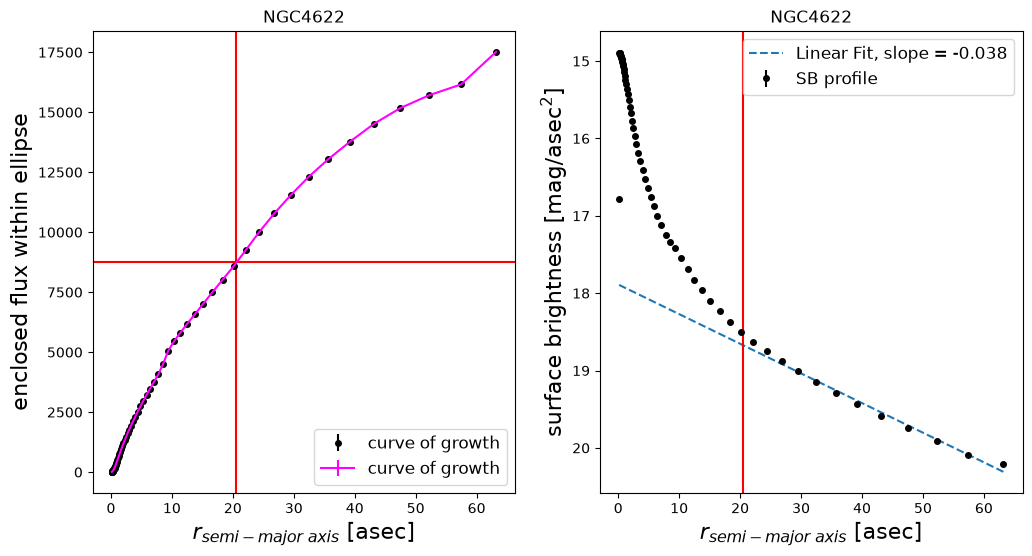

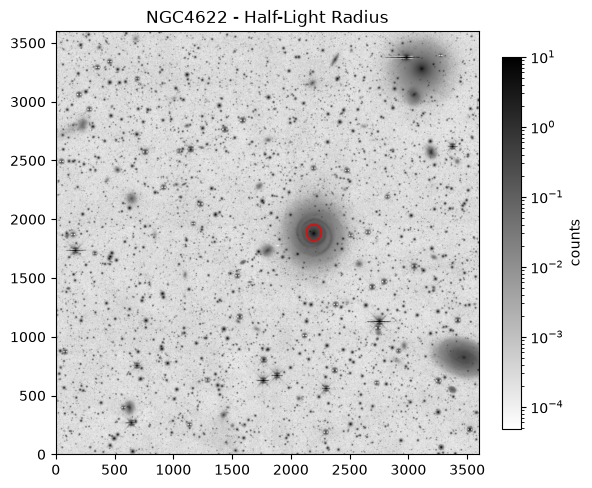

In [163]:
galname = 'NGC4622'

#we will use the isophote shape that corresponds to the average isophote values from the previous section
#xcenav[galname], ycenav[galname], epsav[galname], paav[galname]

#the magnitude zeropoint of the image, such that mag = -2.5 * log(flux) + magzp
magzp = header[galname]['MAGZERO']

#The pixel scale from the header converted from degrees to asec
pixscale = header[galname]['CD2_2'] * 3600.    #in asec/pix

#Go through every aperture and measure the surface brightness between it and the next most outer isophote
#initialize arrays for surface brightness and bin center
rcent = np.array([])
sbcent = np.array([])
sbcent_err = np.array([])
totflux = np.array([])
totflux_err = np.array([])
for aindx, a_out in enumerate(isolist[galname].sma):

    #skip the first isophote because I will always compute the values between the current isophote and the previous
    if aindx==0:
        a_in = 0.01

    if aindx>0:
        #create the inner and outer minor axes from the major axes and ellipticity
        b_out = a_out * (1.-epsav[galname])
        b_in = a_in * (1.-epsav[galname])

        #print(f'a_out = {a_out:.2f}; a_in ={a_in:.2f}; b_out ={b_out:.2f}; b_in ={b_in:.2f}')
        #set up elliptical annulus using parameters at rhalf
        annulus_aperture = EllipticalAnnulus((xcenav[galname],ycenav[galname]), 
                                             a_in, a_out, b_out, b_in = b_in,
                                             theta = paav[galname])
        total_aperture = EllipticalAperture((xcenav[galname],ycenav[galname]), 
                                             a_out, b_out, theta = paav[galname])
        aperstats_ann = ApertureStats(data[galname],annulus_aperture)
        aperstats_tot = ApertureStats(data[galname],total_aperture)
        a_in = a_out

        #the central radius of each annulus in asec.  I'm appending each central radius to the existing array
        rcent = np.append(rcent, (a_in + a_out) / 2.*pixscale)
        #the average pixel flux within each annulus
        avflux = aperstats_ann.mean
        #the standard deviation of the pixel values within each annulus
        stdflux = aperstats_ann.std
        #the number of pixels in each annulus
        numpix = aperstats_ann.sum_aper_area

        #Now do the total within each aperture
        totflux = np.append(totflux,aperstats_tot.sum)
        totflux_err = np.append(totflux_err,aperstats_tot.std)
        
        #****************************
        #your code here
        #the area of a pixel
        pixarea = pixscale**2 ## gives a result in asec^2 / pix^2
        
        #determine the average surface brightness in mag/asec^2.

        #totMag = -2.5 * log(totflux) + magzp # flux adds linearly, magnitudes do not. 
        totMag = -2.5 * np.log10(totflux[aindx-1]) + magzp ## index minus one since the loop index and the array index are ofset by one. 
        
        #avMag = totMag + 2.5log10(A) where A is the area of the annulus
        surfaceArea = pixarea * numpix ## surface area of annulus
        surfaceArea = surfaceArea / u.pix 
        surfaceArea = surfaceArea / u.pix ## fixing units 
        avMag = totMag + 2.5 * np.log10( surfaceArea ) 
        
        #avFluxErr = sqrt( (partial avMag / partial total flux * total flux error)**2 ), partial avMag / partial total flux = -2.5 / ( totflux * np.log(10)) # the partial derivative of log_10(x) = 1/(x * ln(x)) by change of base formula for logs
        
        #avMag = avMag * u.pix #* u.pix ## doing this for the same reason as for avflux_err
        sbcent = np.append(sbcent, avMag)
        # the uncertainty in the mean flux (this is not the standard deviation of all the pixels in the aperture).  
        # Check back to Homework 1
        avflux_err = np.sqrt( ( ( totflux_err[aindx-1] * -2.5 ) / ( totflux[aindx-1] * np.log(10) ) )**2 ) ## again adjusting the index as with the definition of totMag
        avflux_err = avflux_err #* u.pix  * u.pix #this gets rid of the units on the flux error so that the next part works
        sbcent_err = np.append(sbcent_err, avflux_err)

fig,ax = plt.subplots(1,2,figsize=(12, 6))

#plot the semi-major axis vs. magnitude
ax[1].errorbar(rcent, sbcent, yerr=sbcent_err, 
             fmt='o', markersize=4, color='black', label='SB profile')

## begin disk / bulge profile fitting: 
model_x = rcent[-1-10:] #eyeballing this 
model_y = sbcent[-1-10:]
fit = LS(model_x, model_y)
slopeLabel = f'Linear Fit, slope = -{fit[0]:.3f}'
ax[1].plot([rcent[0], rcent[-1]], [fit[0] * rcent[0] + fit[1],  fit[0] * rcent[-1] + fit[1] ], '--', label= slopeLabel)
print(f'Central disk brightness: {fit[1]:.3f} +- {fit[3]:.3f}')

## end disk / bulge profile fitting: 

ax[1].invert_yaxis()

ax[1].legend(fontsize=12)

ax[1].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[1].set_ylabel('surface brightness [mag/asec$^2$]',fontsize=16)
ax[1].set_title(galname)

#plot the curve of growth
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='o', markersize=4, color='black', label='curve of growth')
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='-', markersize=4, color='magenta', label='curve of growth')

#ax[0].axvline(rhalfasec[galname], color='red', label='$r_{half}$')
ax[0].legend(fontsize=12)

ax[0].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[0].set_ylabel('enclosed flux within ellipse',fontsize=16)
ax[0].set_title(galname)

#measure the half-light radius
#a horizontal line at half the total flux
ax[0].axhline(totflux[-1]/2., color='red')

#a vertical line at half the total flux
#*************************
#You will need to adjust rhalfpix by eye to get the radius that encompasses half the light.
#you shoul do this using the plot you make, not using the image itself.
rhalfasec[galname] = 20.5
ax[0].axvline(rhalfasec[galname], color='red')
print(f'the half-light radius = {rhalfasec[galname]:.3f} [asec]')

#plot the same line on the surface brightness plot
ax[1].axvline(rhalfasec[galname], color='red', label='$r_{half}$')

#calculate and print the surface brightness somewhere within 3 arcsec from the center.  
#Note that some of the inner values have NaNs because the isophote fitting failed there.  
#Just keep going out in index until you get a valid value
#***********************
#your code here
centerIndex = 3 ## for ease of use
#print(sbcent[centerIndex:centerIndex+10])
print(f'Surface brightness near center: ',sbcent[centerIndex]) 


#calculate and print out the surface brightness at the effective radius
#***********************
#your code here
#print('rcent length: ', len(rcent))
#print('rcent[52] : ',rcent[52]) ## finding the right index... 
halfRadIndex = 52
print('Surface brightness near the effective radius: ', sbcent[halfRadIndex] )

#find the isophote that best corresponds to the half-light radius
#We will do this by computing the difference between the half-light radius
#and the semi-major axis of each isophote.  
diff = rcent - rhalfasec[galname]

#this returns the index of the isophote that is closes to the half-light radius
#We use this to set the ellipticity and PA of the isophotes
rhalfasecind = np.argmin(abs(diff))


#
print('isophote index that is closest to the half-light radius: ', rhalfasecind)

#calculate and print out the ratio of the **flux** surface brightness between the center and at r_half
#***********************
#your code here
flux_rat = totflux[halfRadIndex] / totflux[centerIndex]

## calculate uncertanity: flux_rat_err = sqrt( ( partial ratio / partial flux_SB(rhalf) * flux_SB(rhalf)_err )**2 + ( partial ratio / partial flux_SB(rcent) * flux_SB(rcent)_err )**2 )

## partial ratio / partial flux_SB(rhalf) = 1 / flux_SB(rcent)
par_f_half = 1 / totflux[halfRadIndex]

## partial ratio / partial flux_SB(rcent) = -flux_SB(rhalf) / (flux_SB(rcent))**2
par_f_cent = -totflux[halfRadIndex] / ( totflux[centerIndex] )**2

ratio_uncert = np.sqrt( ( par_f_half * totflux_err[halfRadIndex] )**2 + ( par_f_cent * totflux_err[centerIndex] )**2 )

#print('length of totflux: ', len(totflux))
print(f'flux_SB(rhalf) / flux_SB(rcent) = {flux_rat:.3f} +- {ratio_uncert:.3f}')

# plotting the isophote over the image: 
print('Counts scale range:') ## print to make the output look a bit less cluttered
## taking some code from cell [75] and using it to plot only one isophote:
fig,ax = imdisplay(data[galname], 42, 99.99, logscale=True) ## plotting the image TODO: crop these haha

aperiter = EllipticalAperture((isolist[galname].x0[rhalfasecind], isolist[galname].y0[rhalfasecind]), isolist[galname].sma[rhalfasecind], 
                                      isolist[galname].sma[rhalfasecind] * (1-isolist[galname].eps[rhalfasecind]), isolist[galname].pa[rhalfasecind]) ## grabbing the correct isophote
aperiter.plot(ax,color='red') # plotting the isophote 
ax.set_title(galname+" - Half-Light Radius")
    
        



These final plots are the radial profiles and half-light radius profiles for each of the galaxies. Using the Least Squares method, we calculated the central disk brightness for each galaxy. Then, we created ellipse profiles by using central surface brightness and central radius, and this allowed us to determine how brightness changes with distance (i.e., semimajor axis). As expected, as apertures increase in size, they contain more light, hence the enclose flux vs semimajor axis plot having an increasing trend (larger ellipse = more light). We also plot surface brightness against semimajor axis for each galaxy, with a linear fit to each. As expected, as semimajor axis (i.e., distance) increases, surface brightness decreases. We find that the central disk brightness for our sample has an average value of 18.192 +/- 0.022 magnitudes, and our values vary by a sample size standard deviation of 0.517. 